# 07 · 噪声与纠错：用 3 个比特保护 1 个比特

对应讲义实验 F · 约 30 分钟 · 前置：01 编程基础

真实的量子比特会出错。本节先在模拟器里加入噪声，再用最简单的纠错码——重复码——把错误率压下去，体会纠错的基本规律：**只要物理错误率低于阈值，码距越大，逻辑错误越少**。

**学完本节，你将能够**
- 在线路中加入噪声信道，比较理想与含噪的结果；
- 用重复码与多数表决降低逻辑错误率，并推导理论公式；
- 用症状比特和经典解码器定位错误，而不破坏量子叠加。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from mindquantum import Circuit, H, X, RY, Simulator, Hamiltonian, QubitOperator
from mindquantum import BitFlipChannel, DepolarizingChannel, PhaseFlipChannel
from mqlab import check

## 1. 噪声：同一个 Bell 态，理想与含噪

`DepolarizingChannel(p)` 以概率 p 让比特变得完全随机（随机作用 I、X、Y、Z 之一）。在 CNOT 之后，给两个比特各加一个 p = 5% 的去极化信道：

In [2]:
bell = Circuit([H.on(0), X.on(1, 0)])
noise = DepolarizingChannel(0.05)          # 以 5% 的概率完全随机化
noisy = bell + noise.on(0) + noise.on(1)
for name, c in [('理想', bell), ('含噪', noisy)]:
    c = c.copy()
    c.measure_all()
    res = Simulator('mqvector', 2).sampling(c, shots=1000, seed=42)
    print(name, res.data)

理想 {'00': 500, '11': 500}
含噪 {'00': 478, '01': 27, '10': 16, '11': 479}


含噪时出现了 `01` 和 `10`，两个比特不再总是一致。

在态矢量后端 `mqvector` 上，噪声信道以“轨迹采样”的方式模拟：每次采样随机决定是否出错。今天最好的硬件，两比特门的错误率约为 $10^{-3}$；而一个有用的算法需要上亿次操作——只靠改进硬件远远不够，必须纠错。

## 2. 重复码：编码、出错、多数表决

最简单的想法：把一个比特复制成 3 份（$|1\rangle \to |111\rangle$），读出时少数服从多数。只要出错的比特不超过一个，就能得到正确答案。

量子态不能复制（不可克隆定理），但可以用 CNOT 把 $\alpha|0\rangle + \beta|1\rangle$ 编码成 $\alpha|000\rangle + \beta|111\rangle$。下面先编码 $|1\rangle$，让每个比特独立地以概率 p 翻转（`BitFlipChannel`），再测量并多数表决。

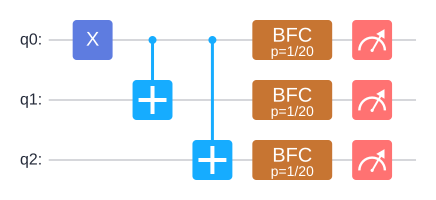

In [3]:
def repetition(d, p):
    circ = Circuit([X.on(0)])                  # 逻辑比特 |1⟩
    for i in range(1, d):
        circ += X.on(i, 0)                     # 编码：|1⟩ → |1…1⟩
    for i in range(d):
        circ += BitFlipChannel(p).on(i)        # 以概率 p 翻转
    circ.measure_all()
    return circ

def logical_error(d, p, shots=100_000, seed=1):
    sim = Simulator('mqvector', d)
    res = sim.sampling(repetition(d, p), shots=shots, seed=seed)
    wrong = sum(n for bits, n in res.data.items()
                if bits.count('1') <= d // 2)  # 多数表决出错
    return wrong / shots

repetition(3, 0.05).svg()

In [4]:
for p in [0.01, 0.05, 0.1]:
    print(f'p = {p:.2f}：逻辑错误率 {logical_error(3, p):.2%}')

p = 0.01：逻辑错误率 0.03%
p = 0.05：逻辑错误率 0.77%


p = 0.10：逻辑错误率 2.83%


### 练习 1 · 理论公式

码距为 d 的重复码，只有**超过一半**的比特翻转时，多数表决才会出错。补全 `theory(d, p)`，返回逻辑错误率。提示：恰好 k 个比特翻转的概率是 $\binom{d}{k}p^k(1-p)^{d-k}$（`comb(d, k)`）。

In [5]:
def theory(d, p):
    # 练习 1
    ### BEGIN SOLUTION
    return sum(comb(d, k) * p ** k * (1 - p) ** (d - k) for k in range(d // 2 + 1, d + 1))
    ### STUDENT: return ...
    ### END SOLUTION

check.repetition_theory(theory)

✅ 通过：理论公式正确


### 现场改一改：先预测，再运行

每一处先写下预测：

1. p = 0.6 时，码距 d = 1、3、5：码距越大，逻辑错误会？　A 越少　B 差不多　C 越多
2. d = 5、p = 5%：逻辑错误率约为？　A 1%　B 0.1%　C 0.01%
3. 把 `BitFlipChannel` 换成 `PhaseFlipChannel`：码距 3 能比码距 1 保护得更好吗？　A 能　B 一样　C 反而更差（答案在第 5 节）

In [6]:
for d in [1, 3, 5]:
    print(f'p = 0.6，d = {d}：{logical_error(d, 0.6):.3f}')
print(f'p = 0.05，d = 5：{logical_error(5, 0.05):.3%}')

p = 0.6，d = 1：0.601
p = 0.6，d = 3：0.648


p = 0.6，d = 5：0.684
p = 0.05，d = 5：0.098%


<details><summary>答案</summary>

1. C：0.601、0.648、0.684。每个比特都更可能出错时，多数表决反而更可能选错：高于阈值，越纠越错（下一节的图）。
2. B：约 0.1%（实测 0.098%，理论 0.116%）。d = 1 时 5%，d = 3 时 0.77%，d = 5 时约 0.1%：每多 2 个比特，错误率降一个量级左右。
</details>

## 3. 码距越大，抑制越强——前提是低于阈值

比较 d = 1、3、5、7：点是模拟结果，线是理论公式（完成练习 1 后显示）。

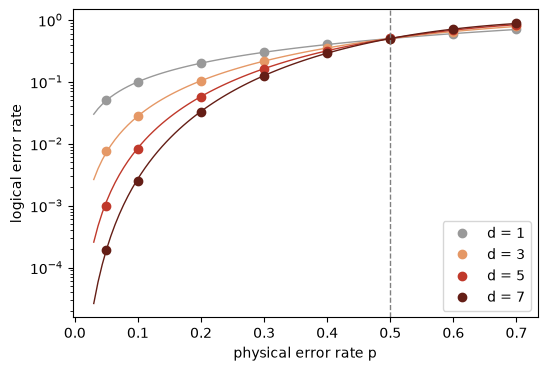

In [7]:
ps = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
plt.figure(figsize=(6, 4))
for d, color in zip([1, 3, 5, 7], ['0.6', '#e59866', '#c0392b', '#641e16']):
    plt.semilogy(ps, [logical_error(d, p) for p in ps], 'o', color=color, label=f'd = {d}')
    if theory(1, 0.1) is not ...:
        pp = np.linspace(0.03, 0.7, 100)
        plt.semilogy(pp, [theory(d, p) for p in pp], color=color, lw=1)
plt.axvline(0.5, color='0.5', ls='--', lw=1)
plt.xlabel('physical error rate p')
plt.ylabel('logical error rate')
plt.legend()
plt.show()

所有曲线在 p = 0.5 交于一点，这是这个简化模型的**阈值**：低于阈值时，增大码距能把错误率压到任意低；高于阈值（虚线右侧），纠错反而越纠越错。真实硬件上表面码的阈值约为 1%。2024 年，Google 的 Willow 芯片首次在表面码上实现了“码距 3 → 5 → 7、逻辑错误率逐级下降”，每增加 2 个码距，错误率降为约 1/2.14。

## 4. 症状与解码器：不看数据，也能找到错误

多数表决要直接测量数据比特，这会破坏量子叠加。真正的纠错只测量**奇偶校验**：

- $s_0 = q_0 \oplus q_1$，$s_1 = q_1 \oplus q_2$，用两个辅助比特 $q_3$、$q_4$ 和 CNOT 得到；
- 症状 $(s_0, s_1)$ 指出哪个比特出了错，却不泄露逻辑信息；
- 根据症状决定纠正哪个比特的经典程序，叫做**解码器**。

下面用 RY(1.0) 制备一个叠加态作为逻辑比特，编码后在不同位置注入一个比特翻转，再测症状：

In [8]:
def encode_and_check(error_on=None):
    circ = Circuit([RY(1.0).on(0), X.on(1, 0), X.on(2, 0)])  # 编码
    if error_on is not None:
        circ += X.on(error_on)                  # 注入一个比特翻转
    circ += Circuit([X.on(3, 0), X.on(3, 1)])   # s0 = q0 ⊕ q1
    circ += Circuit([X.on(4, 1), X.on(4, 2)])   # s1 = q1 ⊕ q2
    return circ

for err in [None, 0, 1, 2]:
    sim = Simulator('mqvector', 5)
    sim.apply_circuit(encode_and_check(err))
    ket = sim.get_qs(ket=True).replace('\n', '  ')
    print(f'错误位置 {str(err):>4}：{ket}')

错误位置 None：0.87758256¦00000⟩  0.47942554¦00111⟩
错误位置    0：0.87758256¦01001⟩  0.47942554¦01110⟩
错误位置    1：0.87758256¦11010⟩  0.47942554¦11101⟩
错误位置    2：0.47942554¦10011⟩  0.87758256¦10100⟩


比特串按 $q_4 q_3 q_2 q_1 q_0$ 书写，前两位是症状 $(s_1, s_0)$。无论错误在哪里，两项的症状都相同——症状是确定的，而数据比特上的叠加 $\alpha$、$\beta$ 完好无损。

### 练习 2 · 写一个解码器

补全 `decode(s0, s1)`：返回需要翻转的比特编号（0、1、2），不需要纠正时返回 `None`。

In [9]:
def decode(s0, s1):
    # 练习 2
    ### BEGIN SOLUTION
    return {(0, 0): None, (1, 0): 0, (1, 1): 1, (0, 1): 2}[(s0, s1)]
    ### STUDENT: return ...
    ### END SOLUTION

check.decoder(decode)

✅ 通过：解码器正确：四种症状各自对应唯一的纠正操作


把解码器接到线路上：读出症状，按解码结果纠正，再和没有出错的编码态比较。

In [10]:
encoded = Simulator('mqvector', 3)
encoded.apply_circuit(Circuit([RY(1.0).on(0), X.on(1, 0), X.on(2, 0)]))
target = encoded.get_qs()                       # 没有出错的编码态

for err in [None, 0, 1, 2]:
    sim = Simulator('mqvector', 5)
    sim.apply_circuit(encode_and_check(err))
    idx = int(np.argmax(np.abs(sim.get_qs())))  # 症状是确定的，任取一项
    s0, s1 = (idx >> 3) & 1, (idx >> 4) & 1
    fix = decode(s0, s1)
    if fix is ...:
        print('请先完成练习 2')
        break
    if fix is not None:
        sim.apply_gate(X.on(fix))               # 纠正
    data = sim.get_qs().reshape(4, 8)[2 * s1 + s0]  # 数据比特的分量
    fid = abs(np.vdot(target, data)) ** 2
    print(f'错误 {str(err):>4} → 症状 ({s0}, {s1}) → 纠正 {fix}，保真度 {fid:.3f}')

错误 None → 症状 (0, 0) → 纠正 None，保真度 1.000
错误    0 → 症状 (1, 0) → 纠正 0，保真度 1.000
错误    1 → 症状 (1, 1) → 纠正 1，保真度 1.000
错误    2 → 症状 (0, 1) → 纠正 2，保真度 1.000


## 5. 思考：重复码能防相位翻转吗？

量子比特还有一种经典比特没有的错误：相位翻转 Z（$|+\rangle \leftrightarrow |-\rangle$）。把逻辑 $|+\rangle$ 编码为 $(|000\rangle + |111\rangle)/\sqrt{2}$，用逻辑算符 $X_0X_1X_2$ 的期望值衡量信息是否保存完好（没有错误时为 1）。这里用密度矩阵后端 `mqmatrix` 精确计算。

In [11]:
p = 0.05
for d in [1, 3]:
    circ = Circuit([H.on(0)] + [X.on(i, 0) for i in range(1, d)])
    circ += Circuit([PhaseFlipChannel(p).on(i) for i in range(d)])
    logical_x = Hamiltonian(QubitOperator(' '.join(f'X{i}' for i in range(d))))
    value = Simulator('mqmatrix', d).get_expectation(logical_x, circ).real
    print(f'd = {d}   <X…X> = {value:.3f}')

d = 1   <X…X> = 0.900
d = 3   <X…X> = 0.729


码距 3 反而更差（现场改一改第 3 处的答案是 C）：任何一个比特的相位翻转都会翻转逻辑相位，重复码对此无能为力。要同时防住比特翻转和相位翻转，需要更强的码：Shor 码用 9 个比特做到了这一点；今天的主流是**表面码**，码距 d 需要约 $2d^2$ 个物理比特，症状每微秒测量一次，解码器必须实时跟上。

## 小结

- 噪声让结果偏离理想分布；纠错用冗余换取可靠性。
- 低于阈值时，码距越大，逻辑错误率越低——这是所有纠错方案的共同规律。
- 纠错的核心是软件：解码器要根据症状又快又准地推断错误，这是今天量子软件最活跃的方向之一。